In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random. default_rng (35)
from scipy.stats import norm,multivariate_normal

Given:

$\bar{p}_\star(x, y) = \left(x^2 + y^2\right)^{k/4 - 1} e^{-\sqrt{x^2 + y^2} / 2}$

Let $r = \sqrt{x^2 + y^2}$ and $\theta = \tan^{-1}\left(\frac{y}{x}\right)
$ $\theta = \tan^{-1}(y/x)$. The Jacobian of the transformation is $
\begin{bmatrix}
\frac{x}{\sqrt{x^2 + y^2}} & \frac{y}{\sqrt{x^2 + y^2}} \\
-\frac{y}{x^2 + y^2} & \frac{x}{x^2 + y^2}
\end{bmatrix}.
$
The determinant of the Jacobian matrix is r, so in polar coordinates:

$\bar{p}_\star(r, \theta) = r^{k/2 - 1} e^{-r / 2}, \quad \text{where } r \geq 0, \theta \in [0, 2\pi).$
Now we sample from:

- r: Gamma-like distribution (marginal)
- θ: Uniform distribution over [0,2π]

1. **Sample r**: The marginal for rr is proportional to:

   $p_r(r) \propto r^{k/2 - 1} e^{-r / 2}$

   This is a Gamma distribution with shape parameter $\alpha = \frac{k}{2}
$ and scale parameter $\beta = 2$. We can directly sample r using standard Gamma distribution sampling methods.

2. **Sample θ**: The conditional distribution of θ is uniform over [0,2π], so we can sample θ directly as:

   $\theta \sim \text{Uniform}(0, 2\pi)$.

3. **Convert back to Cartesian Coordinates**:

   $x = r \cos(\theta), \quad y = r \sin(\theta)$

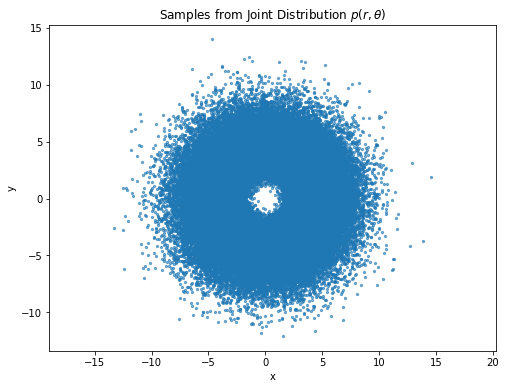

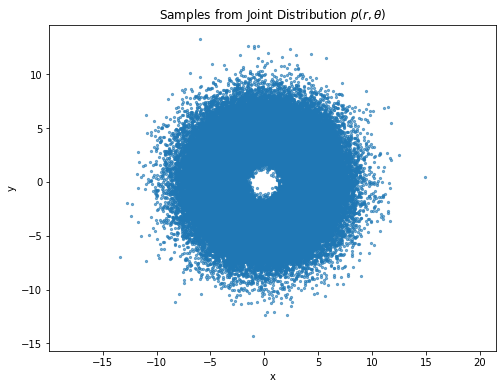

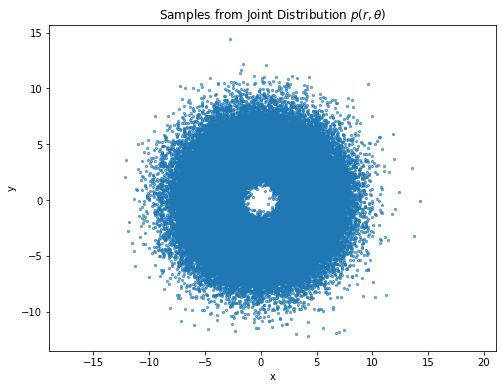

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
def plot_joint_distribution(k_values, N=100000, beta=2):

    r = np.random.gamma(shape=k / 2 , scale=1/beta, size=N)
    theta = np.random.uniform(0, 2 * np.pi, size=N)

    # Convert to Cartesian coordinates
    x = r * np.cos(theta)
    y = r * np.sin(theta)

    # Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(x, y, s=5, alpha=0.6)
    plt.title("Samples from Joint Distribution $p(r, \\theta)$")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.show()
# Example usage
plot_joint_distribution(20,N=100000)
plot_joint_distribution(40,N=100000)
plot_joint_distribution(60,N=100000)



### Density Variation with \(k\)

- As $k$ increases, the parameter $\alpha = k/2$ of the Gamma distribution rises, increasing both the mean and variance of \(r\). This broadens the distribution in the $(x, y)$-plane.
    - **For $k = 20$**: The samples are more concentrated near the origin.
    - **For $k = 40$**: The spread increases, with samples distributed across a wider region.
    - **For $k = 60$**: The samples are even more spread out, reflecting the heavier tail in the radial direction.

### Sampling Efficiency

- The direct sampling method (transforming from polar to Cartesian coordinates) ensures that the samples perfectly represent the target distribution.
- The plots effectively validate the correctness of the sampling method, as the samples align with expectations from the density function $\bar{p}_\star(x, y)$.


### 1.2 random-walk Metropolis-Hasting sampler
- Proposal: $ q\left(x^{\prime}, y^{\prime} \mid x, y\right)=\mathcal{N}\left(\left(x^{\prime}, y^{\prime}\right) \mid(x, y), \sigma^2 I\right) $
where $\sigma^2$ is variance , and $I$ is identity matrix.
- Acceptance Probability: $ \alpha\left((x, y),\left(x^{\prime}, y^{\prime}\right)\right)=\min \left(1, \frac{\bar{p}_{\star}\left(x^{\prime}, y^{\prime}\right)}{\bar{p}_{\star}(x, y)}\right) $ since the proposal distribution is symmetric according to $\bar{p}_{\star}(x, y)$
- rough Algorithm:
    - Input: start from $X_0=(0,0)$
    - Generate new $X'$ from $q\left(x^{\prime}, y^{\prime} \mid x, y\right)$
    - Accept $X^{\prime}$ with probability $\alpha\left((x, y),\left(x^{\prime}, y^{\prime}\right)\right)$.
    - If rejected, set $X_{n+1}=X_n$.
    - repeat $N$ times
    - Burn first 100 samples

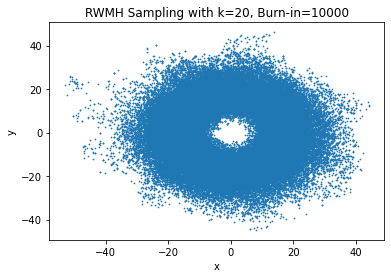

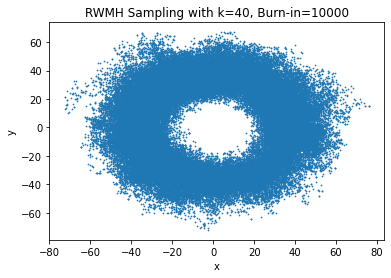

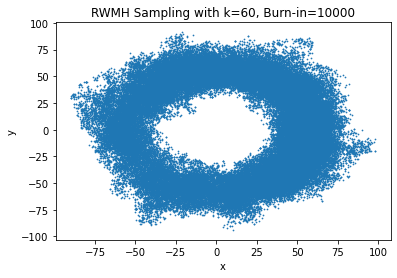

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define log of the target density
def log_target_density(x, y, k):
    r_squared = x**2 + y**2
    if r_squared == 0:  # Avoid singularity
        return -np.inf  # Log of zero
    return (k/4 - 1) * np.log(r_squared) - np.sqrt(r_squared) / 2

# Parameters
n = 100000
rng = np.random.default_rng(35)
burnin=10000
# Initialize sample list and starting point
samplelist = np.zeros((2, n))
samplelist[:, 0] = np.array([4.6, -27.4])
sigma=0.4
# RWMH sampling loop
def rwmh(k,sigma=sigma):
    samplelist = np.zeros((2, n))
    samplelist[:, 0] = np.array([4.6, -27.4])
    for i in range(1, n):
        sample = samplelist[:, i-1] + sigma * rng.normal(0, 5.25, 2)
        u = rng.uniform(0, 1)

    # Compute log acceptance ratio
        log_accept_ratio = (
            log_target_density(sample[0], sample[1], k) -
            log_target_density(samplelist[0, i-1], samplelist[1, i-1], k)
            )

    # Accept or reject the proposed sample
        if np.log(u) < log_accept_ratio:
            samplelist[:, i] = sample
        else:
            samplelist[:, i] = samplelist[:, i-1]
    return samplelist
samplelist=rwmh(20,sigma=sigma)
plt.scatter(samplelist[0, burnin:], samplelist[1, burnin:], s=0.5)
plt.title(f"RWMH Sampling with k=20, Burn-in={burnin}")
plt.xlabel("x")
plt.ylabel("y")
plt.show()
samplelist=rwmh(40,sigma=sigma)
plt.scatter(samplelist[0, burnin:], samplelist[1, burnin:], s=0.5)
plt.title(f"RWMH Sampling with k=40, Burn-in={burnin}")
plt.xlabel("x")
plt.ylabel("y")
plt.show()
samplelist=rwmh(60,sigma=sigma)
plt.scatter(samplelist[0, burnin:], samplelist[1, burnin:], s=0.5)
plt.title(f"RWMH Sampling with k=60, Burn-in={burnin}")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

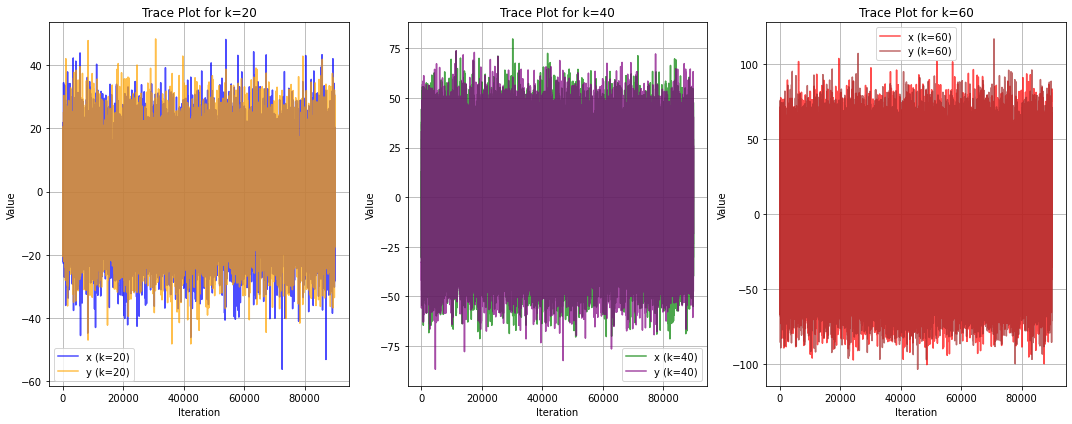

In [ ]:
# Generate samples for different values of k
k_values = [20, 40, 60]
colors_x = ['blue', 'green', 'red']
colors_y = ['orange', 'purple', 'brown']
labels_x = [f"x (k={k})" for k in k_values]
labels_y = [f"y (k={k})" for k in k_values]

plt.figure(figsize=(15, 6))

for idx, k in enumerate(k_values):
    samplelist = rwmh(k, sigma=sigma)

    # Create subplot for each k
    plt.subplot(1, 3, idx + 1)
    plt.plot(samplelist[0, burnin:], label=f"x (k={k})", color=colors_x[idx], alpha=0.7)
    plt.plot(samplelist[1, burnin:], label=f"y (k={k})", color=colors_y[idx], alpha=0.7)
    plt.title(f"Trace Plot for k={k}")
    plt.xlabel("Iteration")
    plt.ylabel("Value")
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()


#### plot discussion
- trace plot suggest samples are independent and keeps moving.
- scatter plot for samples: align well with the density contours, spreads outward (i.e. broader range distribution) when $k$ increase. the donut shape becomes less concentrated on the origin due to in the accept ratio calculation, the larger k causes the log of r becomes a smaller negative number in origin(r will be a number smaller than 1,log of r will be negative),so the samples near origin will be easily rejected.

MALA sampling
$
x_s = x + \gamma \nabla \log p(x) + \sigma \cdot \epsilon
$

where:
- $ \gamma $ is the step size (a small positive value controlling the magnitude of the gradient step).
- $ \nabla \log p(x) $ is the gradient of the log-target density at the current position \( x \), providing the direction of steepest ascent in the log-density.
-$ \sigma = \sqrt{2 \gamma} $ is the noise scale.
- $ \epsilon \sim \mathcal{N}(0, I) $ is a noise vector drawn from a standard normal distribution.

Thus, the Langevin proposal step can be written as:

$
x_s = x + \gamma \nabla \log p(x) + \sqrt{2\gamma} \epsilon
$

Once the Langevin proposal \( x_s \) is generated, we compute the **Metropolis-Hastings acceptance ratio** to decide whether to accept or reject the new sample. The acceptance ratio is given by:

$
\alpha = \min \left(1, \frac{p(x_s)}{p(x)} \cdot \frac{q(x | x_s)}{q(x_s | x)} \right)
$

where:
-$ p(x) $ is the target density.
-$ q(x_s | x) $ is the proposal distribution from $ x $ to $x_s $.
- $ q(x | x_s) $ is the proposal distribution from $ x_s $ to $ x $.



###derive the gradient
\begin{equation}
\text{grad}_x = \left( \frac{k}{4} - 1 \right) \frac{2x}{r^2} - \frac{x}{r}
\end{equation}

\begin{equation}
\text{grad}_y = \left( \frac{k}{4} - 1 \right) \frac{2y}{r^2} - \frac{y}{r}
\end{equation}

\begin{equation}
r^2 = x^2 + y^2
\end{equation}


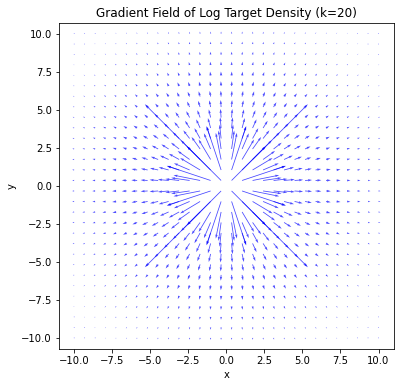

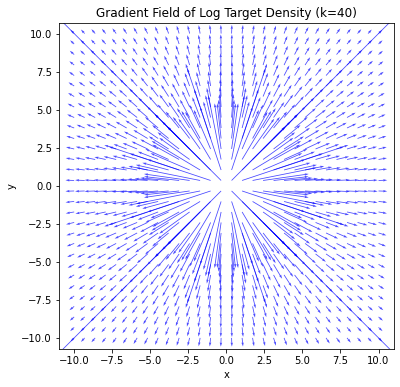

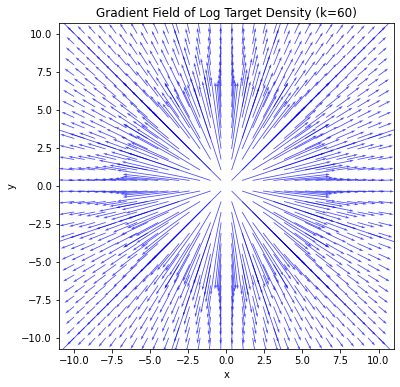

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the gradient function for the log target density
def grad_logtarget(x, y, k):
    epsilon = 1e-8  # Small constant for numerical stability
    r2 = x**2 + y**2 + epsilon
    grad_x = (k / 4 - 1) * (2 * x / r2) - x / (2 * np.sqrt(r2))
    grad_y = (k / 4 - 1) * (2 * y / r2) - y / (2 * np.sqrt(r2))
    return np.array([grad_x, grad_y])

# Parameters
k_values = [20, 40, 60]  # List of k values
grid_size = 30  # Resolution of the grid
x = np.linspace(-10, 10, grid_size)
y = np.linspace(-10, 10, grid_size)
X, Y = np.meshgrid(x, y)

# Plot gradient fields for each k value
for k in k_values:
    # Compute gradient field
    U = np.zeros_like(X)
    V = np.zeros_like(Y)

    for i in range(grid_size):
        for j in range(grid_size):
            grad = grad_logtarget(X[i, j], Y[i, j], k)
            U[i, j] = grad[0]
            V[i, j] = grad[1]

    # Plot gradient field for the current k value
    plt.figure(figsize=(6, 6))
    plt.quiver(X, Y, U, V, scale=50, color='blue', alpha=0.7)
    plt.title(f"Gradient Field of Log Target Density (k={k})")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.show()


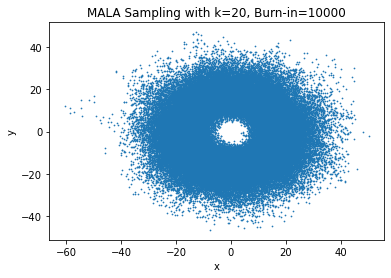

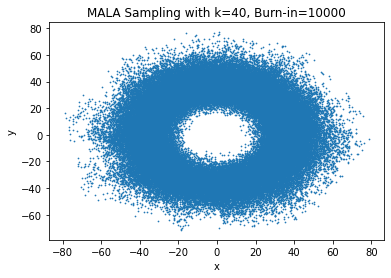

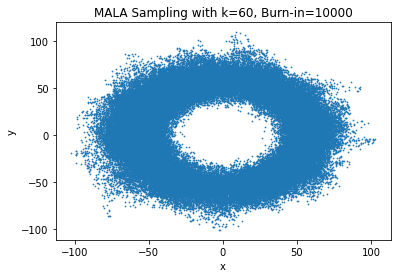

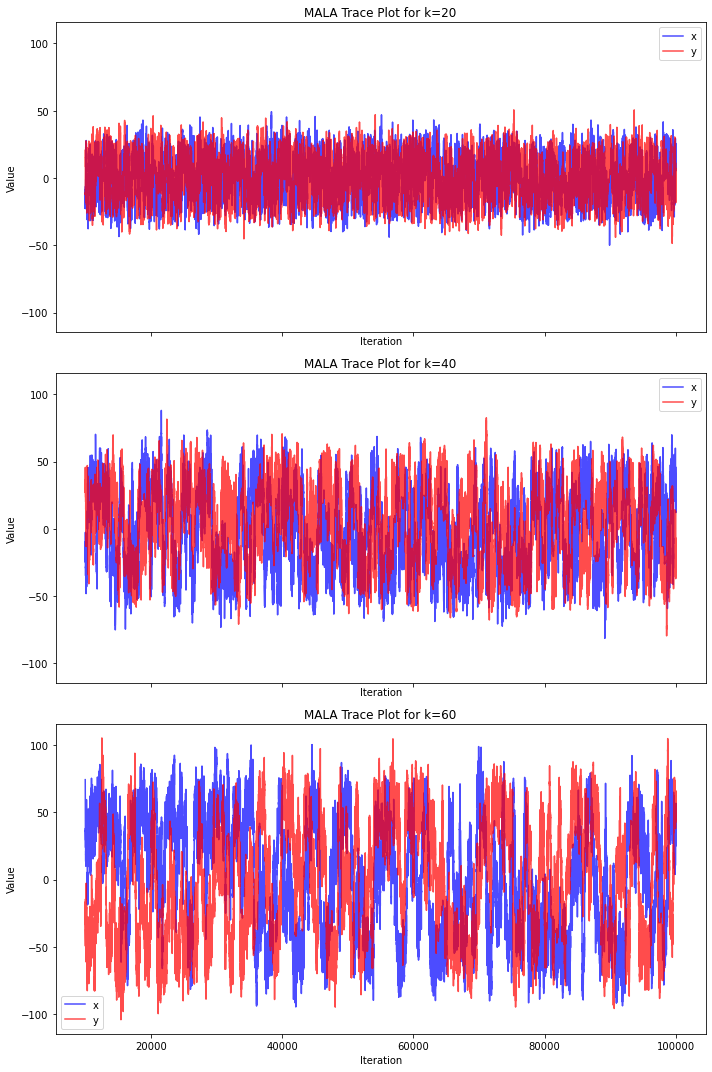

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
n = 100000
burnin = 10000
sigma = 0.4
gamma = 5
k_values = [20, 40, 60]

# MALA Kernel Function
def log_MALA_kernel(x_s, x, gamma, grad_logtarget):
    grad = grad_logtarget(x[0], x[1], k)
    return -(1 / (4 * gamma)) * np.linalg.norm(x_s - x - gamma * grad)**2

# MALA Sampling Process
def mala_sampling_process(gamma, k):
    sigma_langevin = np.sqrt(2 * gamma)
    MALA_samplelist = np.zeros((2, n))
    MALA_samplelist[:, 0] = np.array([-6.8, -15])

    for i in range(1, n):
        sample = MALA_samplelist[:, i-1] + gamma * grad_logtarget(
            MALA_samplelist[0, i-1], MALA_samplelist[1, i-1], k
        ) + sigma_langevin * rng.normal(0, 1, 2)
        u = rng.uniform(0, 1)

        log_accept_ratio = (
            log_target_density(sample[0], sample[1], k) -
            log_target_density(MALA_samplelist[0, i-1], MALA_samplelist[1, i-1], k)
        )
        log_accept_ratio += log_MALA_kernel(
            MALA_samplelist[:, i-1], sample, gamma, grad_logtarget
        ) - log_MALA_kernel(
            sample, MALA_samplelist[:, i-1], gamma, grad_logtarget
        )
        if np.log(u) < log_accept_ratio:
            MALA_samplelist[:, i] = sample
        else:
            MALA_samplelist[:, i] = MALA_samplelist[:, i-1]

    return MALA_samplelist

# Plotting MALA samples for different values of k
for k in k_values:
    samples = mala_sampling_process(gamma, k)
    plt.scatter(samples[0, burnin:], samples[1, burnin:], s=0.5)
    plt.title(f"MALA Sampling with k={k}, Burn-in={burnin}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()
# Create a figure with 3 subplots for the trace plots of different k values
fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True, sharey=True)

for idx, k in enumerate(k_values):
    # Run MALA for each k value
    samples = mala_sampling_process(gamma=gamma, k=k)

    # Plot the trace plot for each k value
    axes[idx].plot(range(burnin, n), samples[0, burnin:], label='x', color='blue', alpha=0.7)
    axes[idx].plot(range(burnin, n), samples[1, burnin:], label='y', color='red', alpha=0.7)

    axes[idx].set_title(f'MALA Trace Plot for k={k}')
    axes[idx].set_xlabel('Iteration')
    axes[idx].set_ylabel('Value')
    axes[idx].legend()

plt.tight_layout()
plt.show()


The trace plots show the samples mixed well, means they are more likely to be sampled independently as we want. Additionally with a larger k the trace plots flutuate with larger amplitude and the more "bouncy" the sampler may appear, with values oscillating rapidly due to the stronger influence of the gradient.

Scatter plot:As the value of k increases, the range becomes larger. With k changed from 20 to 40 to 60 the domut shape was more spread out, less concentrated on the origin. This results in a wider spread of the sampling points as the MALA algorithm explores further away from the center.

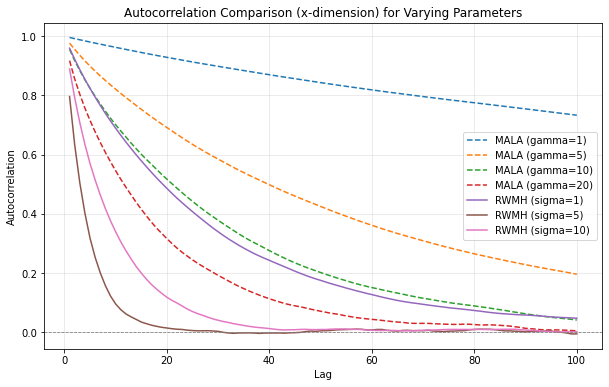

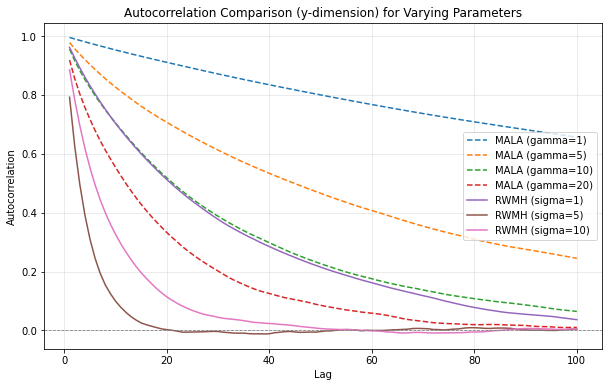

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming your helper functions like `mala_sampling_process`, `rwmh`, etc., are already defined.

def autocorrelation_2d(samplelist, lag):
    mean = np.mean(samplelist, axis=1)
    autocorrelations = []
    for i in range(2):
        samples = samplelist[i]
        mean_i = mean[i]
        cov = np.mean((samples[:-lag] - mean_i) * (samples[lag:] - mean_i))
        var = np.var(samples)
        autocorrelations.append(cov / var)
    return autocorrelations

def compute_autocorrelation_trends(samplelist, max_lag=100):
    """Compute autocorrelation trends for lags 1 to max_lag."""
    trends = {"x": [], "y": []}
    for lag in range(1, max_lag + 1):
        autocorr = autocorrelation_2d(samplelist, lag)
        trends["x"].append(autocorr[0])
        trends["y"].append(autocorr[1])
    return trends

# Varying parameters for MALA and RWMH

gamma_values = [1, 5, 10,20]  # MALA step-size
sigma_values = [1, 5, 10]  # RWMH noise variance

# Initialize plot for MALA and RWMH comparison
plt.figure(figsize=(10, 6))

# Generate and plot MALA samples with different gamma values (step-size)
for gamma in gamma_values:
    mala_samples = mala_sampling_process(gamma=gamma, k=20)[:, burnin:]
    mala_trends = compute_autocorrelation_trends(mala_samples)

    # Plot for x-dimension
    plt.plot(range(1, 101), mala_trends["x"], label=f"MALA (gamma={gamma})", linestyle="--")

# Generate and plot RWMH samples with different sigma values (noise variance)
for sigma in sigma_values:
    rwmh_samples = rwmh(k=20, sigma=sigma)[:, burnin:]
    rwmh_trends = compute_autocorrelation_trends(rwmh_samples)

    # Plot for x-dimension
    plt.plot(range(1, 101), rwmh_trends["x"], label=f"RWMH (sigma={sigma})")

# Customize plot
plt.axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Autocorrelation Comparison (x-dimension) for Varying Parameters")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Repeat the same for y-dimension
plt.figure(figsize=(10, 6))

for gamma in gamma_values:
    mala_samples = mala_sampling_process(gamma=gamma, k=20)[:, burnin:]
    mala_trends = compute_autocorrelation_trends(mala_samples)
    plt.plot(range(1, 101), mala_trends["y"], label=f"MALA (gamma={gamma})", linestyle="--")

for sigma in sigma_values:
    rwmh_samples = rwmh(k=20, sigma=sigma)[:, burnin:]
    rwmh_trends = compute_autocorrelation_trends(rwmh_samples)
    plt.plot(range(1, 101), rwmh_trends["y"], label=f"RWMH (sigma={sigma})")

# Customize plot for y-dimension
plt.axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Autocorrelation Comparison (y-dimension) for Varying Parameters")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The autocorrelations all converge down and a low autocorrelation suggests the samples are independent which is a good property of sampling. MALA sampling converge faster with a larger step size due to the range of target distribution is relatively large so need to adjust the step size.(it can't be too large which causes samples are easily rejected). RWMH performs the best with sigma=5 due to a similar reason. In the graph RWMH is slightly better than MALA.

#question2

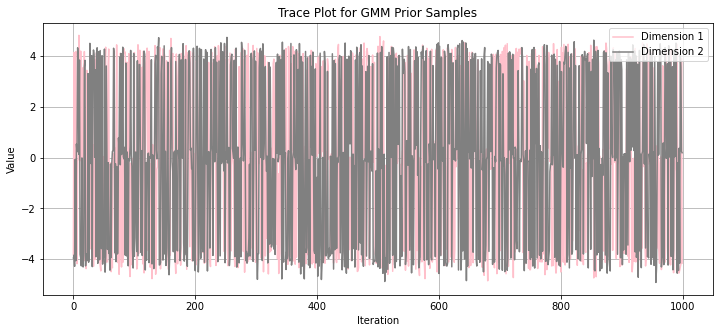

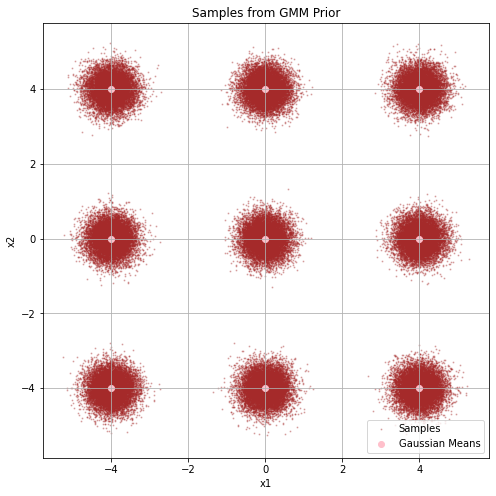

In [ ]:
mu_values = np.array([[4, 0], [0, 4], [-4, 0], [0, -4], [4, 4],
                      [4, -4], [-4, 4], [-4, -4], [0, 0]])
sigma0_squared = 0.1  # Variance of each Gaussian
sigma0 = np.sqrt(sigma0_squared)  # Standard deviation

def sample_gmm_prior(N=100000, burnin=100):
    """
    Exact sampler for the GMM prior.

    Args:
        N (int): Number of samples after burn-in.
        burnin (int): Number of burn-in samples.

    Returns:samples (np.ndarray): Array of shape (N, 2) containing the samples.
    """
    num_components = len(mu_values)
    total_samples = N + burnin
    samples = np.zeros((total_samples, 2))

    for i in range(total_samples):
        # Step 1: Choose a component index uniformly at random
        component = np.random.randint(0, num_components)

        # Step 2: Sample from the chosen Gaussian
        samples[i] = np.random.multivariate_normal(
            mean=mu_values[component], cov=sigma0_squared * np.eye(2)
        )

    # Return samples after burn-in
    return samples[burnin:]
N = 100000
burnin = 100
gmm_samples = sample_gmm_prior(N=N, burnin=burnin)

# Trace plots for each dimension
plt.figure(figsize=(12, 5))
plt.plot(gmm_samples[:1000, 0], label="Dimension 1", color='pink')
plt.plot(gmm_samples[:1000, 1], label="Dimension 2", color='grey')
plt.title("Trace Plot for GMM Prior Samples")
plt.xlabel("Iteration")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.show()

# Scatter plot of the samples
plt.figure(figsize=(8, 8))
plt.scatter(gmm_samples[:, 0], gmm_samples[:, 1], alpha=0.3, s=1, color="brown", label="Samples")
plt.scatter(mu_values[:, 0], mu_values[:, 1], color="pink", label="Gaussian Means")
plt.title("Samples from GMM Prior")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid()
plt.show()


Uniform Component Selection: At each sampling step, a component of the GMM is selected randomly (uniformly) from the available components.
Sampling from the Chosen Gaussian: Once the component is chosen, a sample is drawn from a multivariate normal distribution centered around the selected component's mean with a covariance matrix determined by sigma * I

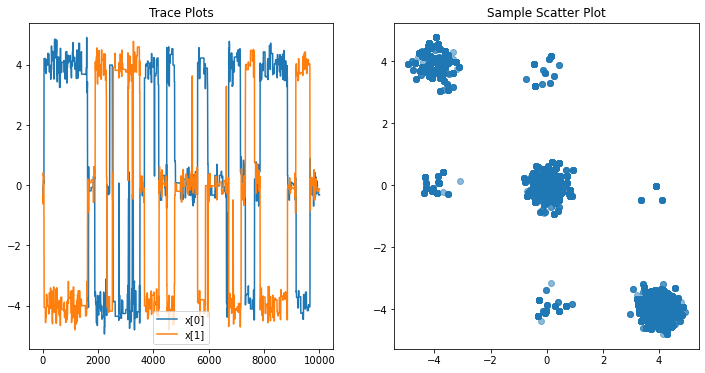

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, norm

# Define parameters
means = np.array([[4, 0], [0, 4], [-4, 0], [0, -4], [4, 4],
                  [4, -4], [-4, 4], [-4, -4], [0, 0]])
sigma1 = 0.1
sigma2 = 2
H = np.array([1, 1])
y = 0

# Gaussian Mixture Model prior
def gmm_prior(x):
    return np.mean([multivariate_normal.pdf(x, mean=mu, cov=sigma1 * np.eye(2)) for mu in means])

# Likelihood
def likelihood(x):
    return norm.pdf(0, loc=np.dot(H, x), scale = np.sqrt(sigma2))

# Posterior
def posterior(x):
    return gmm_prior(x) * likelihood(x)

def metropolis_hastings(num_samples, burnin = 1000):
    current_point = np.array([0, 0])
    samples = [current_point, ]
    total_samples = num_samples + burnin

    for _ in range(total_samples):
        # Propose a new sample using a Gaussian proposal
        proposed_point = current_point + np.random.normal(0, scale = 2 , size=current_point.shape)

        # Compute acceptance probability
        p_current = posterior(current_point)
        p_proposed = posterior(proposed_point)
        acceptance_prob = min(1, p_proposed / p_current)

        # Accept or reject the proposed point
        if np.random.rand() < acceptance_prob:
            current_point = proposed_point

        samples.append(current_point)

    return np.array(samples[burnin:])

# Generate samples
samples = metropolis_hastings(10000)
#
# Plot trace plots and samples
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(samples[:, 0], label='x[0]')
plt.plot(samples[:, 1], label='x[1]')
plt.title('Trace Plots')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(samples[:, 0], samples[:, 1], alpha=0.5)
plt.title('Sample Scatter Plot')
plt.show()

Discuss: Compared with the previous sampling, rwmh shows the samples are dense on the diagonal which align with the target. It's more accurate than 2.1

### 2.3 log-prior and -posterior gradient field & MALA for posterior
#### Log-Prior $\log p(x)$
$$
\log p(x)=\log \left(\frac{1}{9} \sum_{i=1}^9 \mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right)\right) .
$$
where
$$
\mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right)=\frac{1}{2 \pi \sigma_0^2} \exp \left(-\frac{\left(x-\mu_i\right)^T\left(x-\mu_i\right)}{2 \sigma_0^2}\right) .
$$
$$
\nabla \mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right)=-\frac{\left(x-\mu_i\right)}{\sigma_0^2} \mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right) .
$$
and
$$
\nabla \log p(x)=\frac{\sum_{i=1}^9 \nabla \mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right)}{\sum_{i=1}^9 \mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right)} .
$$

Thus:
$$
\nabla \log p(x)=\frac{\sum_{i=1}^9-\frac{\left(x-\mu_i\right)}{\sigma_0^2} \mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right)}{\sum_{i=1}^9 \mathcal{N}\left(x ; \mu_i, \sigma_0^2 I\right)} .
$$
#### Log-Posterior $\log p(x \mid y)$

$$
\log p(x \mid y)=\log p(y \mid x)+\log p(x)
$$
where
$$
\begin{gathered}
p(y \mid x)=\mathcal{N}\left(y ; H x, \sigma^2\right) \\
\log p(y \mid x)=-\frac{1}{2 \sigma^2}(y-H x)^T(y-H x)-\log \sqrt{2 \pi \sigma^2}
\end{gathered}
$$
$$
\nabla \log p(y \mid x)=\frac{H^T(y-H x)}{\sigma^2}
$$
and
$$
\nabla \log p(x \mid y)=\nabla \log p(y \mid x)+\nabla \log p(x)
$$

#### Metropolis-Adjusted Langevin Algorithm (MALA)
MALA proposal is:
$$
q\left(x^{\prime} \mid x\right)=\mathcal{N}\left(x^{\prime} ; x+\gamma \nabla \log p(x \mid y), 2 \gamma I\right),
$$
where $\gamma$ is the step size.\
\
The acceptance probability is:
$$
\alpha\left(x, x^{\prime}\right)=\min \left(1, \frac{p\left(x^{\prime} \mid y\right) q\left(x \mid x^{\prime}\right)}{p(x \mid y) q\left(x^{\prime} \mid x\right)}\right),
$$

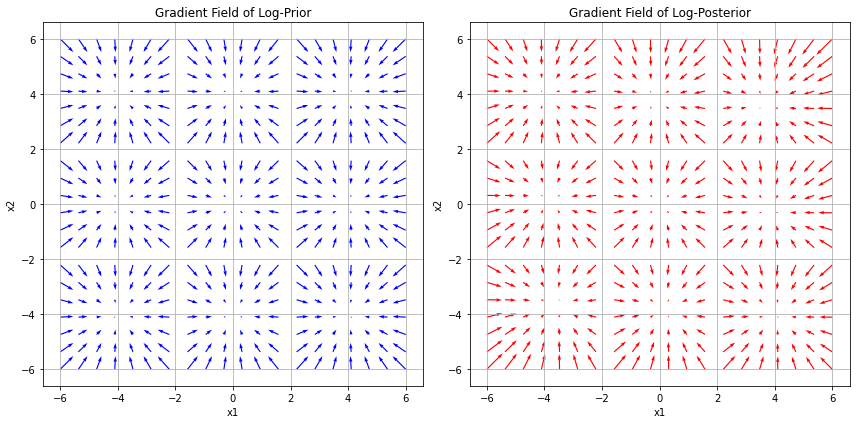

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, norm

# Gaussian Mixture Model means and covariances
means = np.array([[4, 0], [0, 4], [-4, 0], [0, -4], [4, 4],
                  [4, -4], [-4, 4], [-4, -4], [0, 0]])
sigma1 = 0.1
sigma2 = 2
H = np.array([1, 1])
y = 0

# Gradient of log-prior
def grad_log_prior(x,means):
    weighted_gradients = np.zeros(2)
    weights = np.array([
        multivariate_normal.pdf(x, mean=mu, cov=sigma1 * np.eye(2)) for mu in means
    ])
    total_weight = np.sum(weights)
    for i, mu in enumerate(means):
        grad = -np.linalg.inv(sigma1 * np.eye(2)) @ (x - mu)
        weighted_gradients += weights[i] * grad
    return weighted_gradients / total_weight

# Gradient of log-likelihood
def grad_log_likelihood(x):
    residual = y - np.dot(H, x)
    return (1 / sigma2) * residual * H

# Gradient of log-posterior
def grad_log_posterior(x):
    return grad_log_prior(x,means) + grad_log_likelihood(x)

# Create a 2D grid for plotting the vector field
x_vals = np.linspace(-6, 6, 20)
y_vals = np.linspace(-6, 6, 20)
X, Y = np.meshgrid(x_vals, y_vals)
grid_points = np.c_[X.ravel(), Y.ravel()]

# Compute gradients at each grid point
grad_prior = np.array([grad_log_prior(point,means) for point in grid_points])
grad_posterior = np.array([grad_log_posterior(point) for point in grid_points])

# Reshape gradients for plotting
U_prior = grad_prior[:, 0].reshape(X.shape)
V_prior = grad_prior[:, 1].reshape(Y.shape)
U_post = grad_posterior[:, 0].reshape(X.shape)
V_post = grad_posterior[:, 1].reshape(Y.shape)

# Plot the gradient field of the log-prior
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.quiver(X, Y, U_prior, V_prior, color='blue')
plt.title("Gradient Field of Log-Prior")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid()

# Plot the gradient field of the log-posterior
plt.subplot(1, 2, 2)
plt.quiver(X, Y, U_post, V_post, color='red')
plt.title("Gradient Field of Log-Posterior")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid()

plt.tight_layout()
plt.show()


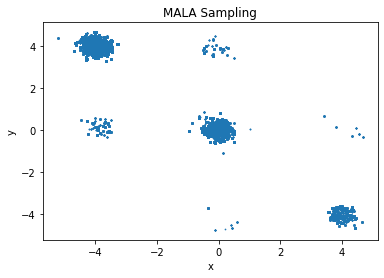

In [ ]:
def log_prior(x):
    gmm_density = np.sum([
        multivariate_normal.pdf(x, mean=mu, cov=0.1 * np.eye(2)) for mu in means
    ])
    return np.log(gmm_density / 9)

def log_likelihood(x):
    return -0.5 * np.log(2 * np.pi * sigma2) - (np.dot(H, x) ** 2) / (2 * sigma2)

def log_posterior(x):
    return log_likelihood(x) + log_prior(x)

def log_MALA_kernel(x_s, x, gamma, grad_log_posterior):
    diff = x_s - x - gamma * grad_log_posterior(x)
    return -(1 / (4 * gamma)) * np.linalg.norm(diff) ** 2

def mala_sampling_process_2(gamma):
    sigma_langevin = np.sqrt(2 * gamma)
    MALA_samplelist = np.zeros((2, n))
    MALA_samplelist[:, 0] = np.array([1, 2])

    for i in range(1, n):
        prev = MALA_samplelist[:, i-1]
        noise = sigma_langevin * rng.normal(0, 1, 2)
        sample = prev + gamma * grad_log_posterior(prev) + noise
        u = rng.uniform(0, 1)

        log_accept_ratio = (
            log_posterior(sample) - log_posterior(prev) +
            log_MALA_kernel(prev, sample, gamma, grad_log_posterior) -
            log_MALA_kernel(sample, prev, gamma, grad_log_posterior)
        )

        if np.log(u) < log_accept_ratio:
            MALA_samplelist[:, i] = sample
        else:
            MALA_samplelist[:, i] = prev

    return MALA_samplelist

# Run MALA sampling
samples = mala_sampling_process_2(gamma=0.6)

# Plot the samples
plt.scatter(samples[0, burnin:], samples[1, burnin:], s=0.5)
plt.title("MALA Sampling")
plt.xlabel("x")
plt.ylabel("y")
plt.show()


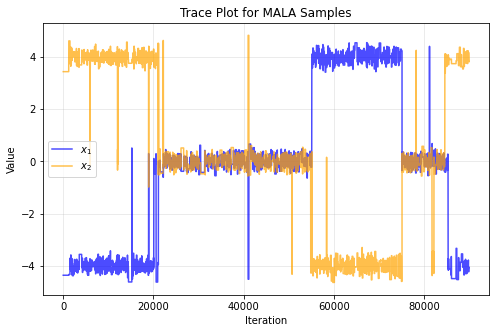

In [ ]:
# Single trace plot for both dimensions
plt.figure(figsize=(8, 5))

# Plot trace for both dimensions
plt.plot(samples[0, burnin:], label="$x_1$", color='blue', alpha=0.7)
plt.plot(samples[1, burnin:], label="$x_2$", color='orange', alpha=0.7)

# Add labels, title, and legend
plt.title("Trace Plot for MALA Samples")
plt.xlabel("Iteration")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


the samples gather on the diagonal which align with the target distribution and performs better than 2.1.However due to the rejection process it needs more time to run the code.

### 2.4 Unadjusted Langevin Algorithm (ULA)
The ULA update rule is:
$$
x_{n}=x_{n-1}+\gamma \nabla \log p\left(x_{n-1} \mid y\right)+\sqrt{2 \gamma} W_n
$$
where:
- $\gamma$ is the step size.
- $\nabla \log p(x \mid y)$ is the gradient of the log-posterior.
- $W_n \sim \mathcal{N}(0, I)$ is a normal distribution for random walk.

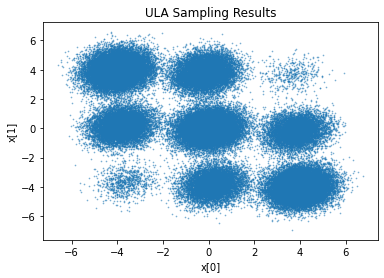

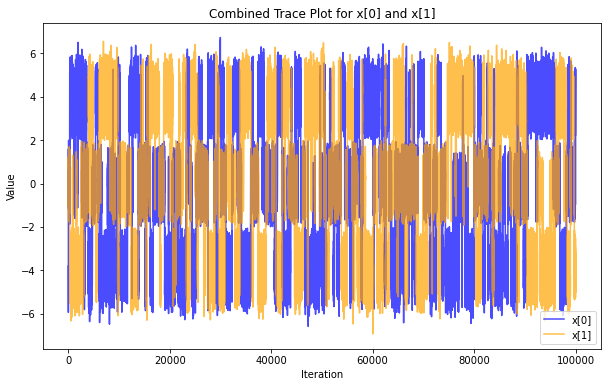

In [ ]:
def ula_sampler(initial, n_samples, step_size, burnin=1000):
    samples = np.zeros((n_samples + burnin, 2))
    samples[0] = initial
    for i in range(1, n_samples + burnin):
        x_current = samples[i - 1]
        grad = grad_log_posterior(x_current)
        noise = np.sqrt(step_size*2) * np.random.normal(size=2)
        samples[i] = x_current + step_size * grad + noise

    return samples[burnin:]

# Run ULA
np.random.seed(42)
initial = np.array([0, 0])  # Initial position
n_samples = 100000  # Number of samples
step_size = 0.15  # Step size
burnin = 1000  # Burn-in period

samples = ula_sampler(initial, n_samples, step_size, burnin)

# Plot the samples
plt.scatter(samples[:, 0], samples[:, 1], s=0.5, alpha=0.5)
plt.title("ULA Sampling Results")
plt.xlabel("x[0]")
plt.ylabel("x[1]")
plt.show()

plt.figure(figsize=(10, 6))

# Plot trace for x[0] and x[1] on the same graph
plt.plot(samples[:, 0], label='x[0]', color='blue', alpha=0.7)
plt.plot(samples[:, 1], label='x[1]', color='orange', alpha=0.7)

# Add titles and labels
plt.title("Combined Trace Plot for x[0] and x[1]")
plt.xlabel("Iteration")
plt.ylabel("Value")
plt.legend()
plt.show()



Discussion: ULA is faster because it doesn't require the acceptance-rejection step, it sacrifices accuracy in the sampling process compared to MALA. In ULA, the samples will likely be more spread out as the graph indicated, they're less likely to gather on the diagonal.
The trace plot shows the process doesn't stuck and keeps moving

Here we use the proposal as standard Gaussian
$$
q(x)=\mathcal{N}\left(x ; \mu, I\right)
$$
#### Weight Calculation
Unnormalized weights for importance sampling are:
$$
w_i=\frac{\bar{p}\left(x_i \mid y\right)}{q\left(x_i\right)}
$$
where $\bar{p}\left(x_i \mid y\right)=p\left(y \mid x_i\right) p\left(x_i\right)$ is the unnormalized posterior. To avoid numerical instability, compute weights in the log-domain:
$$
\log w_i=\log p\left(y \mid x_i\right)+\log p\left(x_i\right)-\log q\left(x_i\right)
$$

Effective Sample Size (ESS): 1055.9845594919045


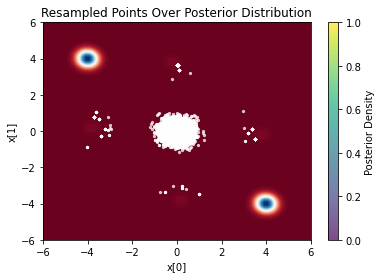

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, norm

# Parameters
means = np.array([[4, 0], [0, 4], [-4, 0], [0, -4],
                  [4, 4], [4, -4], [-4, 4], [-4, -4], [0, 0]])
sigma1 = 0.1
sigma2 = 2
H = np.array([1, 1])
y = 0

# Define prior, likelihood, and posterior
def gmm_prior(x):
    return np.mean([multivariate_normal.pdf(x, mean=mu, cov=sigma1 * np.eye(2)) for mu in means])

def likelihood(x):
    return norm.pdf(y, loc=np.dot(H, x), scale=np.sqrt(sigma2))

def posterior(x):
    return gmm_prior(x) * likelihood(x)

# Proposal distribution: standard Gaussian
def proposal(x):
    return multivariate_normal.pdf(x, mean=np.zeros(2), cov=np.eye(2))

# Log versions for numerical stability
def log_posterior(x):
    log_prior = np.log(gmm_prior(x))
    log_likelihood = np.log(likelihood(x))
    return log_prior + log_likelihood

def log_proposal(x):
    return -0.5 * np.sum(x**2) - np.log(2 * np.pi)

# Effective Sample Size
def ESS(w):
    return 1 / np.sum(w**2)

# Sampling and Resampling
N = 10000
rng = np.random.default_rng(25)

# Sample from proposal
x = rng.normal(0, 1, (2, N))  # 2 x N matrix

# Compute log weights
logW = np.array([log_posterior(x[:, i]) - log_proposal(x[:, i]) for i in range(N)])
logW -= np.max(logW)
w = np.exp(logW) / np.sum(np.exp(logW))

# Compute mean estimate
mean_estimate = np.sum(w * x, axis=1)

# Compute ESS
ess_value = ESS(w)
print("Effective Sample Size (ESS):", ess_value)

# Resample
x_resampled = np.zeros_like(x)
for i in range(N):
    x_resampled[:, i] = x[:, rng.choice(N, p=w)]

# Visualization
# Contour of posterior distribution
x_bb = np.linspace(-6, 6, 100)
y_bb = np.linspace(-6, 6, 100)
X_bb, Y_bb = np.meshgrid(x_bb, y_bb)
Z_bb = np.zeros((100, 100))

for i in range(100):
    for j in range(100):
        Z_bb[i, j] = posterior([X_bb[i, j], Y_bb[i, j]])

plt.contourf(X_bb, Y_bb, Z_bb, levels=100, cmap='RdBu')
plt.scatter(x_resampled[0, :], x_resampled[1, :], s=5, c='white', alpha=0.7)
plt.title("Resampled Points Over Posterior Distribution")
plt.xlabel("x[0]")
plt.ylabel("x[1]")
plt.colorbar(label="Posterior Density")
plt.show()

#The points align with regions of high posterior density, indicating successful resampling.

This amounts to resampling the existing samples w.r.t. their weights. Samples Gather on the diagonal which align with the target. This obtains a new set of samples that are distributed (approximately )according to the target.